# Hierarchical Clustering - UPGMA

---
## Learning Objectives

1. Implement a distance-based phylogeny neighbor joining algorithm
1. Understanding of hierarchical clustering
1. Manipulation of arrays and lists in Python


---
## Imports
You will need to install a two new packages to properly render your phylogenetic trees. Using your preferred package manager, install both [`biopython`](https://biopython.org/) and `matplotlib` into your virtual environments.

For example:
```bash
$ micromamba create -n module06 -c bioconda -c conda-forge python numpy matplotlib biopython
```

In [6]:
import sys
print(sys.executable)
%pip install numpy matplotlib biopython

C:\Users\Aamna\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe
Defaulting to user installation because normal site-packages is not writeable
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------  9.2/9.3 MB 60.3 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 38.8 MB/s  0:00:00
   ---------------------------------------- 0.0/2.7 MB ? eta -:--:--
   ---------------------------------------- 2.7/2.7 MB 16.8 MB/s  0:00:00
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 2.5/2.5 MB 59.9 MB/s  0:00:00
Using cached pyparsing-3.3.3-py3-none-any.whl (126 kB)

   ---------------------------------------- 0/7 [pyparsing]
   -


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: C:\Users\Aamna\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [7]:
from typing import List, Tuple, Dict
from io import StringIO

import matplotlib.pyplot as plt
from Bio import Phylo
import numpy as np

---
## Background

Today we will implement a distance-based phylogenetic tree construction method using the Neighbor-Joining (NJ) algorithm and Smith-Waterman local alignment scores. Unlike UPGMA (Unweighted Pair Group Method using Arithmetic averages), NJ produces unrooted trees and does not assume a constant evolutionary rate across lineages, making it more biologically realistic for analyzing sequence relationships.

We will use HIV-1 reverse transcriptase sequences to construct our phylogenetic tree. The Smith-Waterman algorithm will be used to generate pairwise local alignment scores, which will then be converted into distances for tree construction. This approach is particularly suitable for HIV sequence analysis as it:
1. Handles sequence variations effectively through local alignment
2. Accounts for potential rate heterogeneity across different viral strains
3. Does not assume a molecular clock

The ultimate output will be an unrooted phylogenetic tree representing the evolutionary relationships between the HIV-1 sequences, visualized using the ete3 library. This method provides insights into viral diversity and evolutionary patterns while avoiding the assumptions of simpler hierarchical clustering approaches.

The key innovations of this implementation are:
- Use of Smith-Waterman for sensitive local alignment scoring
- Implementation of Neighbor-Joining for unrooted tree construction
- More biologically realistic evolutionary model

## Neighbor-Joining Algorithm

**Input**: Distance matrix $D$ for $n$ sequences

**Initialization**:
- Let $n$ be the number of sequences
- Assign each sequence $i$ to its own leaf node
- Initialize tree $T$ with leaf nodes

**Iteration**:
While $n > 2$:
1. Calculate Q-matrix where:
   $Q(i,j) = (n-2)d(i,j) - \sum_{k=1}^n d(i,k) - \sum_{k=1}^n d(j,k)$

2. Find pair $(i,j)$ with minimum $Q(i,j)$

3. Calculate branch lengths:
   $d_i = \frac{d(i,j) + (r_i - r_j)/(n-2)}{2}$
   $d_j = d(i,j) - d_i$
   where $r_i = \sum_{k=1}^n d(i,k)$

4. Create new node $k$
   - Add branches from $k$ to $i$ and $j$ with lengths $d_i$ and $d_j$

5. Update distances to remaining nodes $x$:
   $d(k,x) = \frac{d(i,x) + d(j,x) - d(i,j)}{2}$

6. Remove nodes $i$ and $j$
7. Add node $k$ to active nodes
8. $n = n - 1$

**Termination**:
When $n = 2$ with remaining nodes $i$ and $j$:
- Add final branch between $i$ and $j$ with length $d(i,j)$
- Return unrooted tree $T$

---
## Distance metrics for comparing sequences

### Smith-Waterman
This was previously implemented. Feel free to import if you know how...or Copy & Paste.



In [8]:
import numpy as np

In [10]:
def read_fasta(filename: str) -> Dict[str, str]:
    """Reads sequences from FASTA file.

    Args:
        filename (str): Path to FASTA file containing HIV RT sequences

    Returns:
        Dict[str, str]: Dictionary mapping sequence IDs to sequences

    Examples:
        >>> seqs = read_fasta("lafayette_SARS_RT.fasta")
        >>> len(seqs) > 0
        True
    """
    seqs = {}
    current_id = None

    with open(filename) as file:
        for line in file:
            line = line.strip()
            if not line:
                continue

            if line.startswith(">"):  # Identify a new sequence
                current_id = line[1:].split()[0]  # Extract sequence ID
                seqs[current_id] = ""

            elif current_id is not None:
                seqs[current_id] += line  # Add sequence data to the current ID

    return seqs  # Return dictionary of sequences

In [17]:
def cal_score(matrix, seq1, seq2, i, j, match, mismatch, gap):
    '''Calculate score for position (i,j) in scoring matrix, also record move to trace back

    Args:
        matrix (numpy array): scoring matrix
        seq1 (str): sequence 1
        seq2 (str): sequence 2
        i (int): current row number
        j (int): current column number

    Returns:
        score in position (i,j)
        move to trace back: 0-END, 1-DIAG, 2-UP, 3-LEFT

    Pseudocode:
        Calculate scores based on upper-left, up, and left neighbors:
            diag_score = upper-left + (match or mismatch)
            up_score = up + gap
            left_score = left + gap
        score = max(0, diag_score, up_score, left_score)
        traceback = maximum direction or end

    '''
    # Get letters for the cell (-1 for extra border row / column)
    char1 = seq1[i-1]
    char2 = seq2[j-1]

    # Match or mismatch score for pairing the two letters
    if char1 == char2:
        pair_score = match
    else:
        pair_score = mismatch

    # Get scores from the three neighbors
    diag_score = matrix[i-1][j-1] + pair_score # upper-left 2letters
    up_score = matrix[i-1][j] + gap # up; seq1 letter against gap
    left_score = matrix[i][j-1] + gap # left: seq2 letter against gap

    # Best option
    score = max(0, diag_score, up_score, left_score)

    # Record direction the score came from
    if score == 0:
        move = 0 # END
    elif score == diag_score:
        move = 1 # DIAG
    elif score == up_score:
        move = 2 # UP
    else:
        move = 3 # LEFT

    return score, move


def smith_waterman(
    seq1: str,
    seq2: str,
    match: float = 2.0,
    mismatch: float = -1.0,
    gap: float = -1.0
) -> float:
    """Implements Smith-Waterman local alignment algorithm.

    Args:
        sequence1 (str): First HIV RT sequence
        sequence2 (str): Second HIV RT sequence
        match_score (float): Score for matching characters
        mismatch_penalty (float): Penalty for mismatched characters
        gap_penalty (float): Penalty for gaps

    Returns:
        float: Normalized similarity score between sequences

    Examples:
        >>> seq1 = "ACGT"
        >>> seq2 = "ACGT"
        >>> smith_waterman(seq1, seq2)
        1.0
    """
    # Table size to include border row & column with 0s.
    rows = len(seq1) +1
    cols = len(seq2) +1

    # Score table filled with zeros to start
    score_matrix = np.zeros((rows, cols), dtype=int) # avoid the decimals/floats

    # Trace highest score
    max_score = 0

    # Fill in table row by row, left to right
    for i in range(1, rows):
        for j in range(1, cols):
            # Cell's score and arrow
            score, move = cal_score(score_matrix, seq1, seq2, i, j, match, mismatch, gap)
            score_matrix[i][j] = score

            # Note cell if it has highest score so far
            if score > max_score:
                max_score = score

    # NEW FOR PROJECT 6: Normalize score using self-alignment scores
    self_score1 = len(seq1) * match
    self_score2 = len(seq2) * match

    # NEW FOR PROJECT 6: Avoid division by zero
    if self_score1 == 0 or self_score2 == 0:
        return 0.0

    # NEW FOR PROJECT 6: Convert raw score to normalized similarity
    normalized_score = max_score / np.sqrt(self_score1 * self_score2)

    return float(normalized_score)

In [18]:
# prof example test
seq1 = "ACGT"
seq2 = "ACGT"

print(smith_waterman(seq1, seq2))

1.0


In [ ]:
def build_distance_matrix(sequences: Dict[str, str]) -> Tuple[np.ndarray, List[str]]:
    """Builds DISTANCE (not similiarity) matrix using Smith-Waterman scores.

    Args:
        sequences (Dict[str, str]): Dictionary of HIV RT sequences

    Returns:
        Tuple[np.ndarray, List[str]]: Distance matrix and list of sequence IDs

    Examples:
        >>> seqs = read_fasta("lafayette_SARS_RT.fasta")
        >>> mat, ids = build_distance_matrix(seqs)
        >>> mat[0:3, 0:3]  # Show 3x3 slice of distance matrix
        array([[0.000, 0.004, 0.012],
              [0.004, 0.000, 0.012],
              [0.012, 0.012, 0.000]])
        >>> len(ids)  # Number of sequences
        19
    """
    # distance between A and B should equal the distance between B and A so no need to calcuate each pair twice.
    ids = list(sequences.keys())
    n = len(ids)

    # Create an empty distance matrix
    distance_matrix = np.zeros((n, n))

    # Compare each pair of sequences
    for i in range(n):
        for j in range(i + 1, n): # only calculates the upper triangle of the matrix.
            seq1 = sequences[ids[i]]
            seq2 = sequences[ids[j]]

            similarity = smith_waterman(seq1, seq2)

            # Convert similarity to distance
            distance = 1 - similarity

            # Fill both sides of the matrix
            distance_matrix[i][j] = distance
            distance_matrix[j][i] = distance

    return distance_matrix, ids

In [26]:
print("Number of sequences:", len(seqs))
print("Sequence IDs:", list(seqs.keys()))
print("Matrix shape:", mat.shape)



Number of sequences: 20
Sequence IDs: ['gi|24209940|gb|AAN41462.1|', 'gi|24209942|gb|AAN41463.1|', 'gi|24209944|gb|AAN41464.1|', 'gi|24209954|gb|AAN41469.1|', 'gi|24209956|gb|AAN41470.1|', 'gi|24209958|gb|AAN41471.1|', 'gi|24210006|gb|AAN41495.1|', 'gi|24210004|gb|AAN41494.1|', 'gi|24210002|gb|AAN41493.1|', 'gi|24210000|gb|AAN41492.1|', 'gi|24209998|gb|AAN41491.1|', 'gi|24209996|gb|AAN41490.1|', 'gi|24209994|gb|AAN41489.1|', 'gi|24209992|gb|AAN41488.1|', 'gi|24209990|gb|AAN41487.1|', 'gi|24209988|gb|AAN41486.1|', 'gi|24209986|gb|AAN41485.1|', 'gi|24209984|gb|AAN41484.1|', 'gi|24209982|gb|AAN41483.1|', 'gi|24209980|gb|AAN41482.1|']
Matrix shape: (20, 20)


In [27]:
seqs = read_fasta("lafayette_SARS_RT.fasta")
mat, ids = build_distance_matrix(seqs)

print(mat[:3, :3])
print(len(ids))


[[0.         0.00655022 0.04585153]
 [0.00655022 0.         0.03930131]
 [0.04585153 0.03930131 0.        ]]
20


In [35]:
def neighbor_joining(
    distance_matrix: np.ndarray,
    labels: List[str]
) -> str:
    """Implements Neighbor-Joining algorithm for phylogenetic tree construction.

    Args:
        distance_matrix (np.ndarray): Distance matrix from Smith-Waterman scores
        labels (List[str]): Sequence identifiers

    Returns:
        str: Newick format tree string

    Examples:
        >>> seqs = read_fasta("lafayette_SARS_RT.fasta")
        >>> mat, ids = build_distance_matrix(seqs)
        >>> tree = neighbor_joining(mat, ids)
        >>> tree.startswith("((DM1:0.002,DM2:0.002)")  # Start of Newick string
        True
        >>> tree.count(",")  # Number of separators in tree
        18
    """
    # Base case: when only two nodes are left, connect them and finish
    if len(labels) == 2:
        final_distance = distance_matrix[0, 1] / 2
        return f"({labels[0]}:{final_distance},{labels[1]}:{final_distance});"

    n = len(labels)

    # Step 1: Calculate the total distance from each node to all the others
    row_sums = np.sum(distance_matrix, axis=1)

    # Step 2: Find the pair with the smallest corrected distance (D*)
    min_score = float("inf")
    min_i = 0
    min_j = 0

    for i in range(n):
        for j in range(i + 1, n):
            corrected_distance = (n - 2) * distance_matrix[i, j] - row_sums[i] - row_sums[j]

            if corrected_distance < min_score:
                min_score = corrected_distance
                min_i = i
                min_j = j

    # Step 3: Calculate branch lengths for the selected pair
    distance_ij = distance_matrix[min_i, min_j]

    branch_i = 0.5 * distance_ij + (row_sums[min_i] - row_sums[min_j]) / (2 * (n - 2))
    branch_j = distance_ij - branch_i

    # Step 4: Join the pair into a new node using Newick format
    new_node = f"({labels[min_i]}:{branch_i},{labels[min_j]}:{branch_j})"

    # Step 5: Keep the nodes that weren't joined
    remaining = []

    for i in range(n):
        if i != min_i and i != min_j:
            remaining.append(i)

    # Create a smaller distance matrix
    new_distances = np.zeros((n - 1, n - 1))

    # Keep the distances between nodes that weren't joined
    for i in range(len(remaining)):
        for j in range(len(remaining)):
            new_distances[i, j] = distance_matrix[remaining[i], remaining[j]]

    # Calculate distances from the new node to each remaining node
    for i in range(len(remaining)):
        k = remaining[i]

        new_distance = (distance_matrix[min_i, k] + distance_matrix[min_j, k] - distance_ij) / 2

        new_distances[i, -1] = new_distance
        new_distances[-1, i] = new_distance

    # Step 6: Call the function again with one fewer node
    new_labels = [labels[i] for i in remaining] + [new_node]

    return neighbor_joining(new_distances, new_labels)

In [43]:
#small test
test_distances = np.array([
    [0, 5, 9, 9],
    [5, 0, 10, 10],
    [9, 10, 0, 8],
    [9, 10, 8, 0]
], dtype=float)

test_labels = ["A", "B", "C", "D"]

test_tree = neighbor_joining(test_distances, test_labels)
print(test_tree)

((A:2.0,B:3.0):1.5,(C:4.0,D:4.0):1.5);


In [44]:
# big test
tree = neighbor_joining(mat, ids)
print(tree)

((gi|24209998|gb|AAN41491.1|:0.02781710562227075,((gi|24210000|gb|AAN41492.1|:0.05730872452692866,gi|24209986|gb|AAN41485.1|:0.021293895560407547):0.0034400018195051042,(((gi|24209990|gb|AAN41487.1|:0.0002605200476379762,gi|24209984|gb|AAN41484.1|:0.012839916633584761):0.01108381853469188,(gi|24210004|gb|AAN41494.1|:0.0020605895196506383,gi|24209980|gb|AAN41482.1|:0.02414028384279473):0.0020166181465308304):0.004980895196506562,(gi|24209994|gb|AAN41489.1|:0.008242358078602612,(gi|24209940|gb|AAN41462.1|:0.006550218340611327,gi|24209942|gb|AAN41463.1|:-1.3877787807814457e-17):0.017958515283842808):0.000750545851528393):0.004611308224163033):0.002204728438864618):0.00018123976528385335,(gi|24209992|gb|AAN41488.1|:0.024473765010917012,((gi|24209988|gb|AAN41486.1|:0.04733162579778301,(gi|24209944|gb|AAN41464.1|:0.004045723092730569,(gi|24209954|gb|AAN41469.1|:0.0,gi|24209956|gb|AAN41470.1|:0.0):0.009054713588492169):0.011620339267719146):0.01963603399875234,(gi|24209996|gb|AAN41490.1|:0.04

In [45]:
def plot_tree(newick_tree: str) -> None:
    """Plots a phylogenetic tree from a Newick string using Biopython and Matplotlib.

    The tree is rendered in a rectangular layout with smaller leaf labels and
    added margins to reduce overlap between labels and branches.

    Args:
        newick_tree (str): Tree in Newick format

    Returns:
        None: Displays the plotted tree
    """
    handle = StringIO(newick_tree)
    tree = Phylo.read(handle, "newick")

    fig, ax = plt.subplots(figsize=(8, 10))

    Phylo.draw(
        tree,
        axes=ax,
        do_show=False,
        label_func=lambda clade: clade.name if clade.is_terminal() else None,
    )
    for text in ax.texts:
        text.set_fontsize(6)              # shrink labels
    ax.margins(x=0.1, y=0.05)             # extra padding around tree

    plt.tight_layout()
    plt.show()


In [46]:
phylo_tree = Phylo.read(StringIO(tree), "newick")

negative_branches = []

for branch in phylo_tree.find_clades():
    if branch.branch_length is not None and branch.branch_length < 0:
        negative_branches.append(branch.branch_length)

print("Negative branches:", negative_branches)

Negative branches: [-1.3877787807814457e-17]


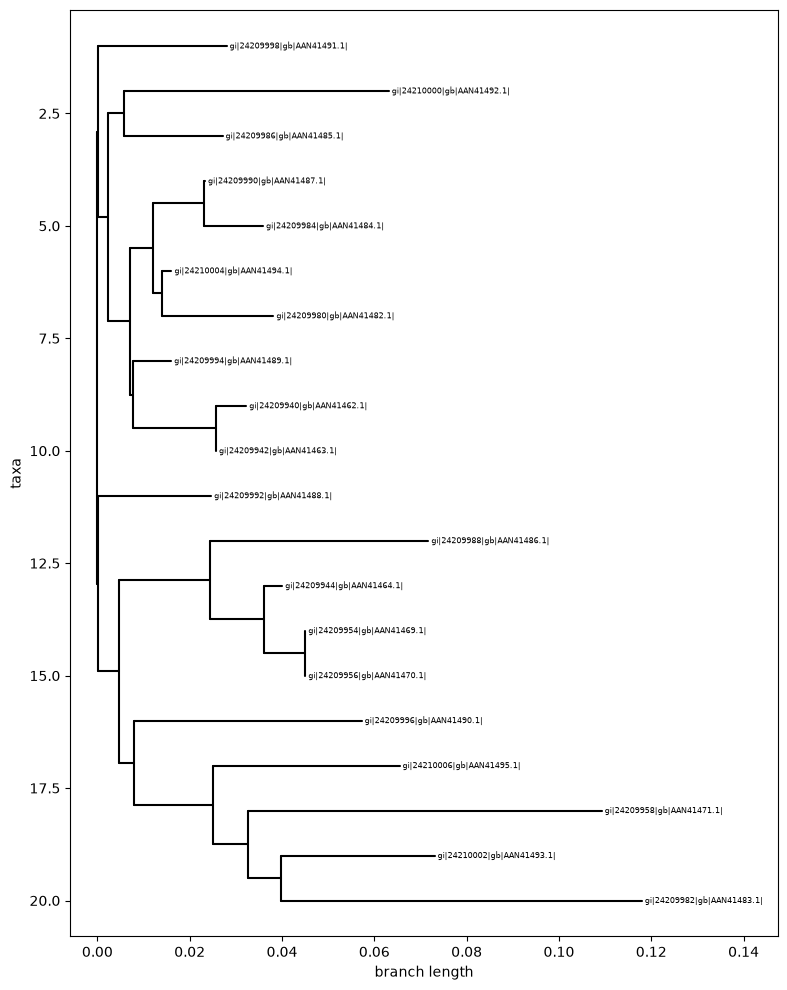

In [47]:
if __name__ == "__main__":
    # Read HIV RT sequences
    sequences = read_fasta("lafayette_SARS_RT.fasta")
    
    # Build distance matrix using Smith-Waterman
    dist_matrix, seq_ids = build_distance_matrix(sequences)
    
    # Generate unrooted tree using Neighbor-Joining
    tree = neighbor_joining(dist_matrix, seq_ids)
    
    # Plot tree
    plot_tree(tree)